# Objective Quest DATAQUEST 5.0 — V5 Forensic/Internal-Signal Attack

This notebook is deliberately **not** another feature-bloated V2/V3 or another model-family shootout.

It follows the evidence accumulated from V1–V4:

- V1/V2 show OOF transfers almost one-to-one to leaderboard.
- Conventional GBDT variants are highly correlated and plateau around QWK ~0.48.
- Questionnaire-path, ontology, single-feature TE, fingerprinting, simple retrieval, and basic deep tabular routes did not produce a qualitative jump.
- Continuous survey sentinel codes should be handled semantically (`NaN + flag`), not blindly clipped.
- The largest remaining legal upside is **forensic structure inside the provided competition files**: submission mapping, quasi-key overlap, repeated household/source structures, and high-purity internal lookup signals.

## V5 thesis

1. **Audit submission mapping from first principles.** `sample_submission.csv` is the official contract and is treated as source-of-truth unless the data prove otherwise.
2. **Audit legal internal quasi-keys.** No external NHIS data, no external labels, no pretrained foundation weights.
3. **Use lookup signal only if it survives honest grouped OOF.** No train/test label peeking.
4. **Use compact models.** Raw-categorical CatBoost + compact LightGBM/XGBoost with a hard feature budget.
5. **Do not submit just because a CSV exists.** A hard diagnostic compares honest OOF to the 0.61541 target.

## Pipeline

1. Problem Understanding  
2. Preprocessing  
3. Fitting for Explainable AI  
4. EDA / forensic EDA  
5. Feature Engineering  
6. Modeling  
7. Evaluation and submission-contract audit

Common tabular pitfalls explicitly avoided:

- more features ≠ better score;
- no scaling for tree models;
- no SMOTE / oversampling;
- no generic median imputation;
- native missingness retained;
- survey special codes are not treated as ordinary continuous values;
- all supervised encodings/lookups are fold-safe.

In [1]:
import os, gc, json, math, warnings, random, hashlib
from pathlib import Path
from dataclasses import dataclass, asdict
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import cohen_kappa_score, mean_squared_error, roc_auc_score
from scipy.optimize import minimize

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostRegressor

warnings.filterwarnings('ignore')
np.set_printoptions(suppress=True, precision=6)
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 180)

print('Environment ready')
print('LightGBM', lgb.__version__, '| XGBoost', xgb.__version__)

Environment ready
LightGBM 4.6.0 | XGBoost 3.2.0


In [2]:
@dataclass
class Config:
    COMPETITION_NAME: str = 'Objective Quest DATAQUEST 5.0'
    VERSION: str = 'v5_forensic'
    TARGET: str = 'life_satisfaction'
    ID_COL: str = 'id'
    HOUSEHOLD_COL: str = 'household_id'
    TRAIN_FILE: str = 'train_final.csv'
    TEST_FILE: str = 'test_final.csv'
    DICT_FILE: str = 'data_dictionary.csv'
    SAMPLE_FILE: str = 'sample_submission.csv'

    SEED: int = 42
    N_FOLDS: int = 5
    USE_GPU: bool = True
    CAT_DEVICES: str = '0:1'

    # Compact model budget
    FINAL_NUMERIC_BUDGET: int = 135
    FS_ESTIMATORS: int = 900
    FS_EARLY_STOPPING: int = 80
    LGB_N_ESTIMATORS: int = 3800
    XGB_N_ESTIMATORS: int = 3800
    CAT_ITERATIONS: int = 3500
    LEARNING_RATE: float = 0.025
    EARLY_STOPPING: int = 180
    VERBOSE: int = 500

    # Raw categorical treatment
    CAT_MAX_UNIQUE: int = 50

    # Forensic key gate
    LOOKUP_MIN_COUNT: int = 2
    LOOKUP_MIN_PURITY: float = 0.80
    LOOKUP_MIN_OOF_COVERAGE: float = 0.01
    LOOKUP_ALPHA_GRID: tuple = (0.0, 0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.55, 0.70, 1.0)
    LOOKUP_MIN_GAIN: float = 0.0015

    # Historical references
    V1_PUBLIC_LB: float = 0.48003
    V2_PUBLIC_LB: float = 0.48193
    TOP1_PUBLIC: float = 0.61541

    EXPECTED_TRAIN_ROWS: int = 95609
    EXPECTED_TEST_ROWS: int = 23902

CFG = Config()
CFG.OUTPUT_DIR = Path('/kaggle/working/oqdq5_v5_forensic')
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(asdict(CFG))

{'COMPETITION_NAME': 'Objective Quest DATAQUEST 5.0', 'VERSION': 'v5_forensic', 'TARGET': 'life_satisfaction', 'ID_COL': 'id', 'HOUSEHOLD_COL': 'household_id', 'TRAIN_FILE': 'train_final.csv', 'TEST_FILE': 'test_final.csv', 'DICT_FILE': 'data_dictionary.csv', 'SAMPLE_FILE': 'sample_submission.csv', 'SEED': 42, 'N_FOLDS': 5, 'USE_GPU': True, 'CAT_DEVICES': '0:1', 'FINAL_NUMERIC_BUDGET': 135, 'FS_ESTIMATORS': 900, 'FS_EARLY_STOPPING': 80, 'LGB_N_ESTIMATORS': 3800, 'XGB_N_ESTIMATORS': 3800, 'CAT_ITERATIONS': 3500, 'LEARNING_RATE': 0.025, 'EARLY_STOPPING': 180, 'VERBOSE': 500, 'CAT_MAX_UNIQUE': 50, 'LOOKUP_MIN_COUNT': 2, 'LOOKUP_MIN_PURITY': 0.8, 'LOOKUP_MIN_OOF_COVERAGE': 0.01, 'LOOKUP_ALPHA_GRID': (0.0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.55, 0.7, 1.0), 'LOOKUP_MIN_GAIN': 0.0015, 'V1_PUBLIC_LB': 0.48003, 'V2_PUBLIC_LB': 0.48193, 'TOP1_PUBLIC': 0.61541, 'EXPECTED_TRAIN_ROWS': 95609, 'EXPECTED_TEST_ROWS': 23902}


## Data loading

The loader searches normal Kaggle competition paths and does not depend on any prior V1–V4 artifacts.

In [3]:
def locate_data_dir():
    roots = [Path('/kaggle/input'), Path('/mnt/data'), Path('.')]
    names = [CFG.TRAIN_FILE, CFG.TEST_FILE, CFG.SAMPLE_FILE]
    for root in roots:
        if not root.exists():
            continue
        # cheap direct candidates first
        candidates = [root, root/'oq-dq-5', root/'competitions'/'oq-dq-5']
        if root.name == 'input':
            candidates += list(root.glob('*'))
        for d in candidates:
            if d.is_dir() and all((d/n).exists() for n in names):
                return d
        for p in root.rglob(CFG.TRAIN_FILE):
            d = p.parent
            if all((d/n).exists() for n in names):
                return d
    raise FileNotFoundError('Could not locate competition CSV files.')

DATA_DIR = locate_data_dir()
print('DATA_DIR:', DATA_DIR)

train = pd.read_csv(DATA_DIR / CFG.TRAIN_FILE)
test = pd.read_csv(DATA_DIR / CFG.TEST_FILE)
sample = pd.read_csv(DATA_DIR / CFG.SAMPLE_FILE)
data_dict = pd.read_csv(DATA_DIR / CFG.DICT_FILE) if (DATA_DIR / CFG.DICT_FILE).exists() else pd.DataFrame()

assert len(train) == CFG.EXPECTED_TRAIN_ROWS, train.shape
assert len(test) == CFG.EXPECTED_TEST_ROWS, test.shape
assert CFG.TARGET in train.columns and CFG.TARGET not in test.columns
assert set(test.columns).issubset(set(train.columns))

y = train[CFG.TARGET].astype(int).to_numpy()
print('train', train.shape, 'test', test.shape, 'sample', sample.shape)
print('target counts:', train[CFG.TARGET].value_counts().sort_index().to_dict())

DATA_DIR: /kaggle/input/competitions/oq-dq-5
train (95609, 179) test (23902, 178) sample (23902, 2)
target counts: {1: 42968, 2: 48189, 3: 3559, 4: 893}


# 1. Problem Understanding

Quadratic Weighted Kappa is ordinal. We therefore model a continuous latent satisfaction score and only discretize at the end. The main validation unit is respondent `id`, because exact duplicate rows share the same ID.

In [4]:
def qwk(y_true, y_pred):
    return float(cohen_kappa_score(np.asarray(y_true, dtype=int), np.asarray(y_pred, dtype=int), weights='quadratic'))

def apply_thresholds(pred, thresholds):
    t = np.sort(np.asarray(thresholds, dtype=float))
    return np.digitize(np.asarray(pred, dtype=float), t) + 1

def optimize_thresholds(y_true, pred, init=(1.55, 2.03, 2.53), maxiter=500):
    y_true = np.asarray(y_true, dtype=int)
    pred = np.asarray(pred, dtype=float)
    def objective(t):
        tt = np.sort(t)
        if tt[0] < 1.0 or tt[-1] > 4.0 or np.min(np.diff(tt)) < 0.03:
            return 10.0
        return -qwk(y_true, apply_thresholds(pred, tt))
    res = minimize(objective, np.asarray(init, float), method='Nelder-Mead', options={'maxiter': maxiter, 'xatol':1e-5, 'fatol':1e-6})
    t = np.sort(res.x)
    return t, -objective(t)

def boundary_auc(y_true, score):
    out = {}
    for cut in [1,2,3]:
        try:
            out[f'auc_gt{cut}'] = float(roc_auc_score((np.asarray(y_true)>cut).astype(int), np.asarray(score)))
        except Exception:
            out[f'auc_gt{cut}'] = np.nan
    return out

groups = train[CFG.ID_COL].astype(str).to_numpy()
sgkf = StratifiedGroupKFold(n_splits=CFG.N_FOLDS, shuffle=True, random_state=CFG.SEED)
folds = list(sgkf.split(train, y, groups=groups))
fold_id = np.full(len(train), -1, dtype=np.int8)
for f, (_, va) in enumerate(folds):
    fold_id[va] = f
print('Fold sizes:', pd.Series(fold_id).value_counts().sort_index().to_dict())

Fold sizes: {0: 19130, 1: 19134, 2: 19113, 3: 19125, 4: 19107}


# 2. Preprocessing

Two distinct views are created:

- **numeric compact view** for LightGBM/XGBoost;
- **raw categorical view** for CatBoost.

For true continuous NHIS-style fields, known sentinel values are converted to missing **only in the numeric continuous view**, with explicit sentinel flags retained. Raw categorical survey codes are not truncated using the simplified dictionary.

In [5]:
# Sentinel codes observed in the competition data / source-style survey encoding.
# They are handled conservatively: only exact known codes are replaced.
CONTINUOUS_SENTINELS = {
    'height_inches': {96,97,98,99},
    'weight_pounds': {996,997,998,999},
    'age': {97,98,99},
    'hours_worked_per_week': {97,98,99,990},
    'days_missed_work': {997,998,999},
    'income_to_poverty_ratio': {110},
}

REDUNDANT_DROP = [
    'data_year',             # survey_year duplicate
    'interview_quarter',     # derived from interview_month
    'food_security_3cat',    # retain 4-cat view
]

FUNCTIONAL_DIFFICULTY_COLS = [
    'difficulty_walking_steps','difficulty_walking_short','difficulty_walking_medium',
    'difficulty_climbing_steps','difficulty_using_hands','difficulty_raising_arm',
    'difficulty_self_care','difficulty_communicating','difficulty_remembering',
    'difficulty_errands_alone','difficulty_social_activities',
]
CHRONIC_CONDITION_COLS = [
    'hypertension_ever','high_cholesterol_ever','heart_disease_ever','heart_attack_ever',
    'angina_ever','stroke_ever','asthma_ever','diabetes_ever','prediabetes_ever',
    'cancer_ever','lung_disease_ever','arthritis_ever','dementia_ever','chronic_fatigue_ever',
]
COST_BARRIER_COLS = [
    'trouble_paying_medical_bills','delayed_care_due_to_cost','skipped_care_due_to_cost',
    'skipped_medication_to_save_money','took_less_medication_to_save_money',
    'delayed_prescription_to_save_money','skipped_prescription_due_to_cost',
    'delayed_therapy_due_to_cost','skipped_therapy_due_to_cost',
]
INCOME_SOURCE_COLS = [
    'has_wage_income','has_investment_income','has_social_security_income','has_disability_income',
    'has_public_assistance_income','has_retirement_income','has_other_income',
]
INSURANCE_COLS = [
    'has_health_insurance','has_private_insurance','has_senior_gov_insurance',
    'has_lowincome_gov_insurance','has_child_gov_insurance','has_military_insurance',
    'has_state_health_plan','has_other_gov_insurance',
]

FORCE_KEEP = [
    'general_health_status','depression_frequency','anxiety_frequency','anxiety_level',
    'difficulty_social_activities','difficulty_remembering','income_to_poverty_ratio',
    'income_poverty_category','food_security_4cat','marital_status_detailed','marital_status',
    'age','survey_weight','row_missing_count','special_code_count',
    'functional_difficulty_count','chronic_condition_count','cost_barrier_count',
    'food_insecurity_burden','income_source_count','insurance_count','mental_frequency_burden',
    'household_size_proxy',
]

def count_yes(df, cols):
    valid=[c for c in cols if c in df.columns]
    return (df[valid] == 1).sum(axis=1).astype(np.int16) if valid else pd.Series(0,index=df.index,dtype=np.int16)

def reverse_ordinal(series, max_valid):
    s=pd.to_numeric(series,errors='coerce')
    out=pd.Series(np.nan,index=s.index,dtype=float)
    mask=s.between(1,max_valid)
    out.loc[mask]=(max_valid+1)-s.loc[mask]
    return out

def build_numeric_view(df):
    out=df.drop(columns=[CFG.TARGET], errors='ignore').copy()
    out['row_missing_count'] = out.drop(columns=[CFG.ID_COL, CFG.HOUSEHOLD_COL], errors='ignore').isna().sum(axis=1).astype(np.int16)

    sentinel_flags=[]
    for c, vals in CONTINUOUS_SENTINELS.items():
        if c in out.columns:
            raw=pd.to_numeric(out[c], errors='coerce')
            flag=raw.isin(vals)
            fc=f'{c}__special_code'
            out[fc]=flag.astype(np.int8)
            sentinel_flags.append(fc)
            out.loc[flag, c]=np.nan
    out['special_code_count'] = out[sentinel_flags].sum(axis=1).astype(np.int16) if sentinel_flags else 0

    out['functional_difficulty_count']=count_yes(out, FUNCTIONAL_DIFFICULTY_COLS)
    out['chronic_condition_count']=count_yes(out, CHRONIC_CONDITION_COLS)
    out['cost_barrier_count']=count_yes(out, COST_BARRIER_COLS)
    out['income_source_count']=count_yes(out, INCOME_SOURCE_COLS)
    out['insurance_count']=count_yes(out, INSURANCE_COLS)

    food=[]
    for c in ['worried_food_would_run_out','food_did_not_last','could_not_afford_balanced_meals']:
        if c in out.columns:
            food.append(reverse_ordinal(out[c],3).fillna(0))
    out['food_insecurity_burden'] = sum(food).astype(np.float32) if food else 0.0
    if 'received_food_assistance' in out.columns:
        out['food_insecurity_burden'] = out['food_insecurity_burden'] + (out['received_food_assistance']==1).astype(np.float32)

    mental=[]
    for c in ['depression_frequency','anxiety_frequency']:
        if c in out.columns:
            mental.append(reverse_ordinal(out[c],5).fillna(0))
    out['mental_frequency_burden'] = sum(mental).astype(np.float32) if mental else 0.0

    hh=[]
    for c in ['children_in_household','adults_in_household']:
        if c in out.columns:
            hh.append(pd.to_numeric(out[c],errors='coerce').fillna(0))
    out['household_size_proxy'] = sum(hh).astype(np.float32) if hh else 0.0

    if 'age' in out.columns:
        age=pd.to_numeric(out['age'],errors='coerce').where(pd.to_numeric(out['age'],errors='coerce').between(18,85))
        out['age_band']=pd.cut(age,[17,24,34,44,54,64,74,85],labels=False,include_lowest=True).astype(float)

    out=out.drop(columns=[CFG.ID_COL, CFG.HOUSEHOLD_COL] + REDUNDANT_DROP, errors='ignore')
    # All supplied fields are numeric-coded; coerce defensively.
    for c in out.columns:
        if not pd.api.types.is_numeric_dtype(out[c]):
            out[c]=pd.to_numeric(out[c], errors='coerce')
    return out

X_num_all = build_numeric_view(train)
X_num_test_all = build_numeric_view(test)
print('Numeric view:', X_num_all.shape)

Numeric view: (95609, 190)


# 3. Fitting for Explainable AI

A cheap fold-0 LightGBM probe is used only to rank features for EDA and to understand what the model already exploits. Final feature selection is relearned inside each outer fold.

In [6]:
probe_tr, probe_va = folds[0]
probe_model = lgb.LGBMRegressor(
    objective='regression_l2', n_estimators=1400, learning_rate=0.035,
    num_leaves=31, min_child_samples=45, colsample_bytree=0.85,
    reg_lambda=4.0, random_state=CFG.SEED, n_jobs=-1, verbosity=-1
)
probe_model.fit(
    X_num_all.iloc[probe_tr], y[probe_tr],
    eval_set=[(X_num_all.iloc[probe_va], y[probe_va])],
    callbacks=[lgb.early_stopping(100, verbose=False)]
)
probe_pred=probe_model.predict(X_num_all.iloc[probe_va], num_iteration=probe_model.best_iteration_)
probe_thr, probe_qwk=optimize_thresholds(y[probe_va], probe_pred, maxiter=250)
probe_imp=pd.DataFrame({
    'feature':X_num_all.columns,
    'importance':probe_model.booster_.feature_importance(importance_type='gain')
}).sort_values('importance',ascending=False)
print('Probe QWK:', probe_qwk, 'thresholds:', probe_thr)
display(probe_imp.head(35))

Probe QWK: 0.4803366098546644 thresholds: [1.572949 1.99363  2.647433]


,feature,importance
65,depression_frequency,38411.014462
141,general_health_status,36147.834810
187,mental_frequency_burden,7523.414129
91,marital_status_detailed,5340.029401
71,anxiety_frequency,4087.353834
5,difficulty_social_activities,4001.854042
97,marital_status,2757.018881
3,income_to_poverty_ratio,2445.061439
54,worry_about_medical_costs,2410.606791
155,anxiety_level,1695.108297


# 4. EDA / Forensic EDA

The EDA is intentionally targeted:

- target balance and missingness;
- special/sentinel codes rather than naive outlier deletion;
- top-feature correlation heatmap and redundancy;
- submission-key contract;
- quasi-key overlap and label purity;
- exact/imputation-invariant fingerprint overlap.

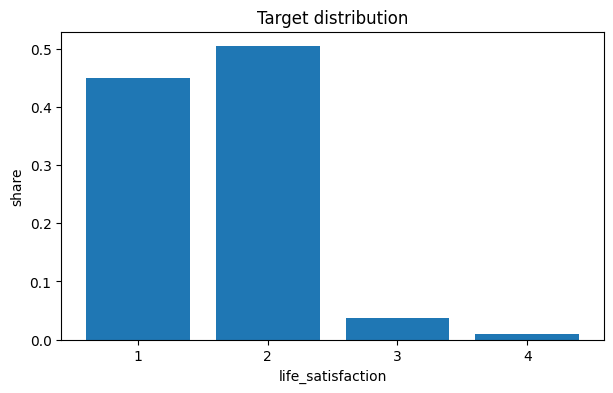

,count,share
life_satisfaction,,
1,42968,0.449414
2,48189,0.504022
3,3559,0.037225
4,893,0.009340


In [7]:
# Target distribution
fig, ax = plt.subplots(figsize=(7,4))
vc=train[CFG.TARGET].value_counts(normalize=True).sort_index()
ax.bar(vc.index.astype(str), vc.values)
ax.set_title('Target distribution')
ax.set_xlabel('life_satisfaction')
ax.set_ylabel('share')
plt.show()

display(pd.DataFrame({'count':train[CFG.TARGET].value_counts().sort_index(), 'share':vc}))

In [8]:
# Missingness hidden signal
miss=pd.DataFrame({
    'train_missing':train.drop(columns=[CFG.TARGET]).isna().mean(),
    'test_missing':test.isna().mean(),
})
miss['abs_gap']=(miss.train_missing-miss.test_missing).abs()
display(miss.sort_values('train_missing',ascending=False).head(30))

row_missing=train.drop(columns=[CFG.TARGET]).isna().sum(axis=1)
miss_by_target=pd.DataFrame({'missing_count':row_missing,'target':y}).groupby('target').missing_count.agg(['mean','median','std'])
display(miss_by_target)

,train_missing,test_missing,abs_gap
flu_vaccine_year,0.538485,0.542800,0.004315
flu_vaccine_month,0.534291,0.540833,0.006543
ever_married,0.521112,0.520919,0.000193
gestational_diabetes_ever,0.500152,0.492051,0.008101
works_full_time,0.485854,0.485692,0.000162
hours_worked_per_week,0.485080,0.484102,0.000978
insurance_marketplace_plan1,0.449884,0.452180,0.002295
days_missed_work,0.440147,0.437871,0.002276
has_paid_sick_leave,0.439645,0.439628,0.000016
employer_offers_insurance,0.439341,0.435361,0.003980


,mean,median,std
target,,,
1,24.673734,23.0,8.557855
2,25.769366,24.0,8.925516
3,29.004496,31.0,8.988843
4,29.874580,32.0,8.857615


In [9]:
# Sentinel audit: do not mistake source codes for physical outliers.
sentinel_rows=[]
for c, vals in CONTINUOUS_SENTINELS.items():
    if c not in train.columns: continue
    for v in sorted(vals):
        ntr=int((train[c]==v).sum())
        nte=int((test[c]==v).sum())
        if ntr+nte:
            sentinel_rows.append({
                'feature':c,'code':v,'train_count':ntr,'test_count':nte,
                'target_mean':float(train.loc[train[c]==v,CFG.TARGET].mean()) if ntr else np.nan
            })
sentinel_audit=pd.DataFrame(sentinel_rows)
display(sentinel_audit)

,feature,code,train_count,test_count,target_mean
0,height_inches,96,5829,1441,1.739578
1,height_inches,97,88,20,1.511364
2,height_inches,98,47,7,1.638298
3,height_inches,99,202,52,1.712871
4,weight_pounds,996,5836,1446,1.738177
5,weight_pounds,997,919,230,1.576714
6,weight_pounds,999,729,158,1.722908
7,age,97,168,43,1.541667
8,age,99,18,4,1.722222
9,hours_worked_per_week,97,81,16,1.518519


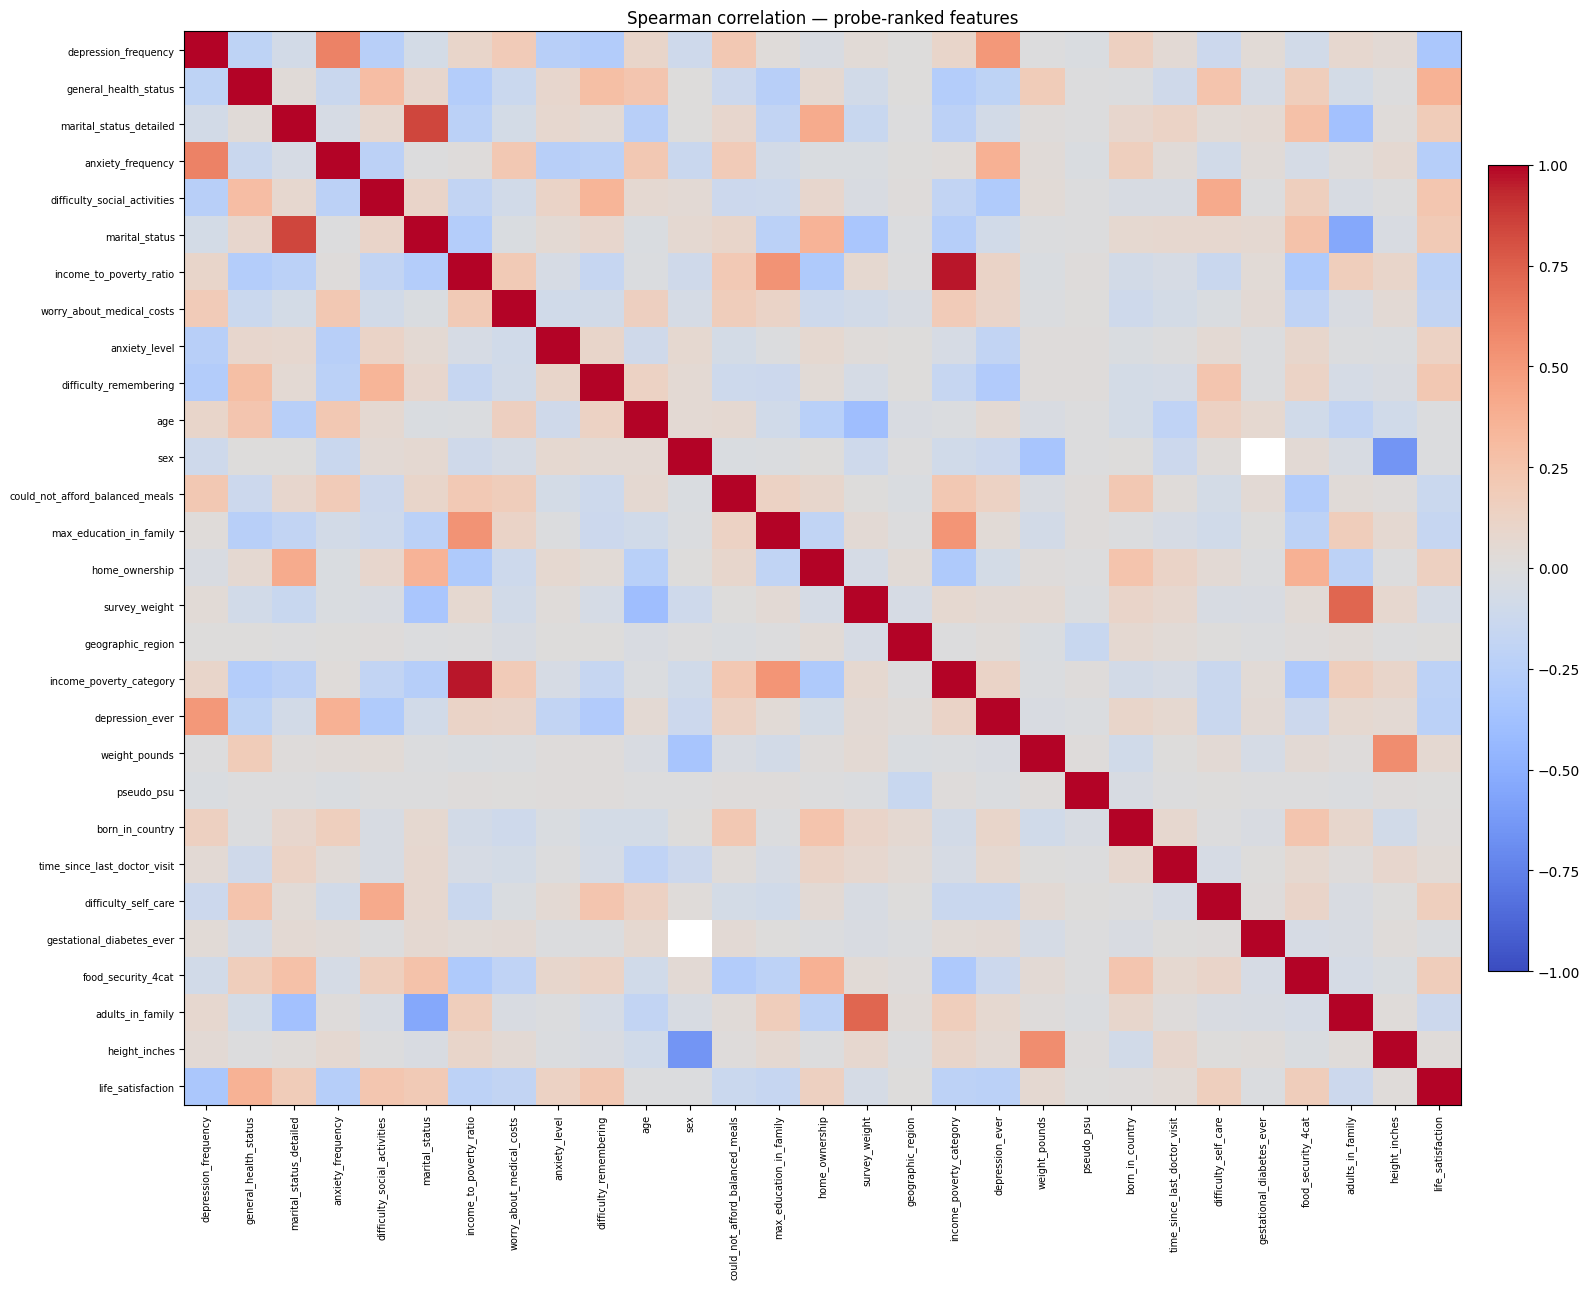

,spearman_with_target
general_health_status,0.361369
depression_frequency,-0.322500
anxiety_frequency,-0.259551
difficulty_social_activities,0.229138
depression_ever,-0.227277
income_to_poverty_ratio,-0.218635
difficulty_remembering,0.216128
income_poverty_category,-0.213499
marital_status,0.196893
marital_status_detailed,0.184169


In [10]:
# Correlation matrix heatmap on probe-ranked numeric features.
top_corr=[c for c in probe_imp.feature if c in train.columns and pd.api.types.is_numeric_dtype(train[c])][:28]
corr=train[top_corr+[CFG.TARGET]].corr(method='spearman')
fig, ax=plt.subplots(figsize=(16,13))
im=ax.imshow(corr.values, aspect='auto', vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(corr.columns))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(corr.index))); ax.set_yticklabels(corr.index, fontsize=7)
ax.set_title('Spearman correlation — probe-ranked features')
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
plt.tight_layout(); plt.show()

target_corr=corr[CFG.TARGET].drop(CFG.TARGET).sort_values(key=np.abs,ascending=False)
display(target_corr.rename('spearman_with_target').to_frame().head(30))

In [11]:
# High redundancy audit supports the hard feature budget.
raw_numeric=[c for c in test.columns if pd.api.types.is_numeric_dtype(train[c]) and c not in [CFG.ID_COL, CFG.HOUSEHOLD_COL]]
rc=train[raw_numeric].corr(method='spearman')
mask=np.triu(np.ones(rc.shape,dtype=bool),1)
pairs=(rc.where(mask).stack().rename('spearman').reset_index().rename(columns={'level_0':'feature_a','level_1':'feature_b'}))
pairs['abs_spearman']=pairs.spearman.abs()
display(pairs.sort_values('abs_spearman',ascending=False).head(35))

,feature_a,feature_b,spearman,abs_spearman
14231,data_year,survey_year,1.000000,1.000000
8486,children_in_family,children_in_household,0.997946,0.997946
14486,ever_used_ecigarette,ecigarette_status,0.996592,0.996592
7845,health_insurance_type,private_health_insurance,0.982371,0.982371
11974,cancer_ever,cancer_types_count,-0.980677,0.980677
14009,smoking_status,ever_smoked,0.978328,0.978328
13544,interview_quarter,interview_month,0.971614,0.971614
524,income_to_poverty_ratio,income_poverty_category,0.961113,0.961113
10777,adults_in_family,adults_in_household,0.959253,0.959253
10876,has_senior_gov_insurance,senior_government_insurance,0.948933,0.948933


## P0 forensic audit: submission mapping

This notebook **does not assume** that `test_final.id` is the submission row identifier.

If the official sample has one row per test row and its IDs differ from `test_final.id`, the primary output follows the official sample row order. A separate unique-`test_final.id` reference file is also produced, but it is not treated as the official submission contract.

In [12]:
expected_row_ids=np.arange(len(train)+1, len(train)+len(test)+1)
map_audit={
    'n_test_rows':int(len(test)),
    'n_sample_rows':int(len(sample)),
    'sample_id_unique':bool(sample['id'].is_unique if 'id' in sample.columns else False),
    'test_id_unique':bool(test[CFG.ID_COL].is_unique),
    'test_unique_id_count':int(test[CFG.ID_COL].nunique()),
    'sample_matches_concat_row_sequence':bool('id' in sample.columns and len(sample)==len(test) and np.array_equal(sample['id'].to_numpy(), expected_row_ids)),
    'sample_id_equals_test_id_rate':float(np.mean(sample['id'].to_numpy()==test[CFG.ID_COL].to_numpy())) if 'id' in sample.columns and len(sample)==len(test) else np.nan,
    'sample_id_min':int(sample['id'].min()) if 'id' in sample.columns else None,
    'sample_id_max':int(sample['id'].max()) if 'id' in sample.columns else None,
    'test_id_min':int(test[CFG.ID_COL].min()),
    'test_id_max':int(test[CFG.ID_COL].max()),
}
print(json.dumps(map_audit, indent=2))

PRIMARY_SUBMISSION_MODE='official_sample_row_order'
assert len(sample)==len(test), 'Official sample must have one row per test prediction for primary export.'

{
  "n_test_rows": 23902,
  "n_sample_rows": 23902,
  "sample_id_unique": true,
  "test_id_unique": false,
  "test_unique_id_count": 23666,
  "sample_matches_concat_row_sequence": true,
  "sample_id_equals_test_id_rate": 0.0,
  "sample_id_min": 95610,
  "sample_id_max": 119511,
  "test_id_min": 3,
  "test_id_max": 118325
}


## Legal quasi-key / internal lookup audit

Each lookup is evaluated **OOF**: for validation fold `f`, labels are aggregated only from the other folds. A lookup is allowed to influence predictions only when the training key has sufficient support and purity.

This tests internal structure without external data.

In [13]:
def key_from_cols(df, cols, round_weight=None):
    parts=[]
    for c in cols:
        if c not in df.columns:
            return None
        s=df[c]
        if c=='survey_weight' and round_weight is not None:
            s=pd.to_numeric(s,errors='coerce').round(round_weight)
        parts.append(s.astype('string').fillna('__NA__'))
    out=parts[0]
    for s in parts[1:]: out=out.str.cat(s, sep='|')
    return out

KEY_SPECS=[
    {'name':'year_weight_exact','cols':['survey_year','survey_weight']},
    {'name':'year_weight_r3','cols':['survey_year','survey_weight'],'round_weight':3},
    {'name':'year_weight_r2','cols':['survey_year','survey_weight'],'round_weight':2},
    {'name':'year_household','cols':['survey_year','household_id']},
    {'name':'household','cols':['household_id']},
    {'name':'year_weight_age_sex','cols':['survey_year','survey_weight','age','sex']},
    {'name':'year_stratum_psu_age_sex','cols':['survey_year','pseudo_stratum','pseudo_psu','age','sex']},
    {'name':'year_weight_stratum_psu','cols':['survey_year','survey_weight','pseudo_stratum','pseudo_psu']},
    {'name':'year_weight_age_sex_health','cols':['survey_year','survey_weight','age','sex','general_health_status']},
]

# Add target-independent exact fingerprints.
INCOME_IMPUTE_COLS=[c for c in test.columns if any(k in c.lower() for k in ['income','poverty','imput','wage','salary','earn'])]
ADMIN_COLS=[c for c in ['survey_weight','pseudo_stratum','pseudo_psu','household_id','survey_year','data_year','interview_month','interview_quarter'] if c in test.columns]

def dataframe_hash_key(df, cols):
    # stable within this notebook run and sufficiently collision-resistant for lookup audit
    h=pd.util.hash_pandas_object(df[cols], index=False).astype('uint64')
    return h.astype('string')

all_noid=[c for c in test.columns if c!=CFG.ID_COL]
no_income=[c for c in test.columns if c not in set([CFG.ID_COL]+INCOME_IMPUTE_COLS)]
no_income_admin=[c for c in test.columns if c not in set([CFG.ID_COL]+INCOME_IMPUTE_COLS+ADMIN_COLS)]
lowcard=[c for c in test.columns if c not in [CFG.ID_COL,CFG.HOUSEHOLD_COL] and train[c].nunique(dropna=True)<=10]

HASH_KEYS={
    'hash_all_noid':(dataframe_hash_key(train,all_noid), dataframe_hash_key(test,all_noid)),
    'hash_no_income':(dataframe_hash_key(train,no_income), dataframe_hash_key(test,no_income)),
    'hash_no_income_admin':(dataframe_hash_key(train,no_income_admin), dataframe_hash_key(test,no_income_admin)),
    'hash_lowcard10':(dataframe_hash_key(train,lowcard), dataframe_hash_key(test,lowcard)),
}

for spec in KEY_SPECS:
    spec['train_key']=key_from_cols(train,spec['cols'],spec.get('round_weight'))
    spec['test_key']=key_from_cols(test,spec['cols'],spec.get('round_weight'))
for name,(ktr,kte) in HASH_KEYS.items():
    KEY_SPECS.append({'name':name,'cols':['<hash>'],'train_key':ktr,'test_key':kte})

forensic_rows=[]
for spec in KEY_SPECS:
    ktr=spec['train_key']; kte=spec['test_key']
    tmp=pd.DataFrame({'key':ktr,'y':y})
    g=tmp.groupby('key').y.agg(['size','nunique','mean'])
    repeated=g[g['size']>=2]
    forensic_rows.append({
        'key_name':spec['name'],
        'train_unique_keys':int(ktr.nunique()),
        'train_repeated_groups':int(len(repeated)),
        'repeated_group_unanimous_rate':float((repeated['nunique']==1).mean()) if len(repeated) else np.nan,
        'test_exact_key_coverage':float(kte.isin(set(ktr)).mean()),
    })
forensic_key_audit=pd.DataFrame(forensic_rows).sort_values('test_exact_key_coverage',ascending=False)
display(forensic_key_audit)

,key_name,train_unique_keys,train_repeated_groups,repeated_group_unanimous_rate,test_exact_key_coverage
4,household,59017,22912,0.415503,0.613338
6,year_stratum_psu_age_sex,83967,9851,0.472338,0.206008
2,year_weight_r2,85648,1870,0.708556,0.104343
1,year_weight_r3,86176,1364,0.821114,0.093047
0,year_weight_exact,86176,1364,0.821114,0.093047
3,year_household,86847,1076,0.889405,0.082587
5,year_weight_age_sex,87905,1852,0.550216,0.081918
7,year_weight_stratum_psu,89980,3177,0.486623,0.074889
8,year_weight_age_sex_health,90221,2680,0.552985,0.067777
9,hash_all_noid,94663,946,1.000000,0.000000


In [14]:
def compute_oof_lookup(ktr, kte, min_count=CFG.LOOKUP_MIN_COUNT, min_purity=CFG.LOOKUP_MIN_PURITY):
    oof=np.full(len(train),np.nan,dtype=float)
    oof_purity=np.full(len(train),np.nan,dtype=float)
    test_fold_preds=[]
    test_fold_purity=[]

    for f,(tr_idx,va_idx) in enumerate(folds):
        tmp=pd.DataFrame({'key':ktr.iloc[tr_idx].to_numpy(), 'y':y[tr_idx]})
        stats=tmp.groupby('key').y.agg(['count','mean'])
        class_counts=tmp.groupby(['key','y']).size().unstack(fill_value=0)
        purity=class_counts.max(axis=1)/class_counts.sum(axis=1)
        stats['purity']=purity
        good=stats[(stats['count']>=min_count)&(stats['purity']>=min_purity)]

        kval=ktr.iloc[va_idx]
        oof[va_idx]=kval.map(good['mean']).to_numpy(dtype=float)
        oof_purity[va_idx]=kval.map(good['purity']).to_numpy(dtype=float)

        kt=kte
        test_fold_preds.append(kt.map(good['mean']).to_numpy(dtype=float))
        test_fold_purity.append(kt.map(good['purity']).to_numpy(dtype=float))

    # final test lookup must be trained on all train data; fold-average above is only a stability diagnostic.
    tmp=pd.DataFrame({'key':ktr.to_numpy(), 'y':y})
    stats=tmp.groupby('key').y.agg(['count','mean'])
    cc=tmp.groupby(['key','y']).size().unstack(fill_value=0)
    purity=cc.max(axis=1)/cc.sum(axis=1)
    stats['purity']=purity
    good=stats[(stats['count']>=min_count)&(stats['purity']>=min_purity)]
    test_final=kte.map(good['mean']).to_numpy(dtype=float)
    test_final_purity=kte.map(good['purity']).to_numpy(dtype=float)

    return {
        'oof':oof,'oof_purity':oof_purity,
        'test':test_final,'test_purity':test_final_purity,
        'oof_coverage':float(np.isfinite(oof).mean()),
        'test_coverage':float(np.isfinite(test_final).mean()),
        'full_good_key_count':int(len(good)),
    }

LOOKUP_RESULTS={}
lookup_rows=[]
for spec in KEY_SPECS:
    r=compute_oof_lookup(spec['train_key'],spec['test_key'])
    LOOKUP_RESULTS[spec['name']]=r
    mask=np.isfinite(r['oof'])
    mae=float(np.mean(np.abs(y[mask]-r['oof'][mask]))) if mask.any() else np.nan
    lookup_rows.append({
        'key_name':spec['name'],'oof_coverage':r['oof_coverage'],'test_coverage':r['test_coverage'],
        'mean_abs_error_on_covered':mae,'good_keys_full_train':r['full_good_key_count']
    })
lookup_audit=pd.DataFrame(lookup_rows).sort_values(['oof_coverage','mean_abs_error_on_covered'],ascending=[False,True])
display(lookup_audit)

,key_name,oof_coverage,test_coverage,mean_abs_error_on_covered,good_keys_full_train
4,household,0.051972,0.074847,0.522681,9529
8,year_weight_age_sex_health,0.015354,0.017404,0.439055,1576
6,year_stratum_psu_age_sex,0.014130,0.019747,0.516196,4668
7,year_weight_stratum_psu,0.013994,0.016609,0.548279,1618
5,year_weight_age_sex,0.008388,0.005774,0.520627,1058
2,year_weight_r2,0.000523,0.000711,0.520000,1325
0,year_weight_exact,0.000314,0.000460,0.400000,1120
1,year_weight_r3,0.000314,0.000460,0.400000,1120
3,year_household,0.000031,0.000042,0.666667,957
9,hash_all_noid,0.000000,0.000000,NaN,946


# 5. Feature Engineering / Selection

The final numeric view is deliberately compact. Selection is learned inside each outer training fold via a small LightGBM importance probe. Engineered features are not automatically forced en masse.

In [15]:
def fold_feature_select(Xtr, ytr, seed, budget=CFG.FINAL_NUMERIC_BUDGET):
    a,b=train_test_split(np.arange(len(Xtr)),test_size=0.18,random_state=seed,stratify=ytr)
    fs=lgb.LGBMRegressor(
        objective='regression_l2',n_estimators=CFG.FS_ESTIMATORS,learning_rate=0.04,
        num_leaves=31,min_child_samples=45,colsample_bytree=0.85,reg_lambda=4,
        random_state=seed,n_jobs=-1,verbosity=-1
    )
    fs.fit(Xtr.iloc[a],ytr[a],eval_set=[(Xtr.iloc[b],ytr[b])],
           callbacks=[lgb.early_stopping(CFG.FS_EARLY_STOPPING,verbose=False)])
    imp=pd.Series(fs.booster_.feature_importance(importance_type='gain'),index=Xtr.columns).sort_values(ascending=False)
    selected=list(imp.head(budget).index)
    forced=[c for c in FORCE_KEEP if c in Xtr.columns]
    # Hard cap: forced features replace tail rather than expanding feature count.
    selected=list(dict.fromkeys(forced + selected))[:budget]
    return selected, imp

# 6. Modeling

Three deliberately different tree views:

- **LightGBM**: compact cleaned numeric view;
- **XGBoost**: same compact numeric view but different booster;
- **CatBoost all-categorical**: low-card raw survey codes are categorical; true continuous fields remain numeric and get sentinel cleaning.

The high-cardinality `id` and `household_id` are never fed as arbitrary numeric model features. Household/source information is evaluated separately by the forensic lookup expert.

In [16]:
def make_lgb(seed):
    return lgb.LGBMRegressor(
        objective='regression_l2',n_estimators=CFG.LGB_N_ESTIMATORS,learning_rate=CFG.LEARNING_RATE,
        num_leaves=31,min_child_samples=40,subsample=0.9,subsample_freq=1,colsample_bytree=0.85,
        reg_alpha=0.03,reg_lambda=5.0,random_state=seed,n_jobs=-1,verbosity=-1
    )

def make_xgb(seed,use_gpu=True):
    p=dict(objective='reg:squarederror',eval_metric='rmse',n_estimators=CFG.XGB_N_ESTIMATORS,
           learning_rate=CFG.LEARNING_RATE,max_depth=6,min_child_weight=8,subsample=0.88,
           colsample_bytree=0.85,reg_alpha=0.03,reg_lambda=5.0,tree_method='hist',random_state=seed,
           n_jobs=-1,early_stopping_rounds=CFG.EARLY_STOPPING)
    if use_gpu: p['device']='cuda'
    return xgb.XGBRegressor(**p)

def make_cat(seed,use_gpu=True):
    p=dict(loss_function='RMSE',eval_metric='RMSE',iterations=CFG.CAT_ITERATIONS,
           learning_rate=CFG.LEARNING_RATE,depth=7,l2_leaf_reg=7.0,random_strength=0.35,
           random_seed=seed,od_type='Iter',od_wait=CFG.EARLY_STOPPING,allow_writing_files=False,
           verbose=CFG.VERBOSE)
    if use_gpu: p.update(task_type='GPU',devices=CFG.CAT_DEVICES)
    else: p.update(task_type='CPU',thread_count=-1)
    return CatBoostRegressor(**p)

def prepare_catboost_view(df):
    base=df.drop(columns=[CFG.TARGET],errors='ignore').copy()
    base=base.drop(columns=[CFG.ID_COL,CFG.HOUSEHOLD_COL]+REDUNDANT_DROP,errors='ignore')
    cat_cols=[]
    for c in base.columns:
        nun=train[c].nunique(dropna=True) if c in train.columns else base[c].nunique(dropna=True)
        if nun<=CFG.CAT_MAX_UNIQUE:
            cat_cols.append(c)
            base[c]=base[c].map(lambda v:'__MISSING__' if pd.isna(v) else str(v))
        else:
            base[c]=pd.to_numeric(base[c],errors='coerce')
            if c in CONTINUOUS_SENTINELS:
                base.loc[base[c].isin(CONTINUOUS_SENTINELS[c]),c]=np.nan
    return base,cat_cols

def fit_lgb(Xtr,ytr,Xv,yv,Xt,seed):
    m=make_lgb(seed)
    m.fit(Xtr,ytr,eval_set=[(Xv,yv)],callbacks=[lgb.early_stopping(CFG.EARLY_STOPPING,verbose=False)])
    return m,m.predict(Xv,num_iteration=m.best_iteration_),m.predict(Xt,num_iteration=m.best_iteration_)

def fit_xgb(Xtr,ytr,Xv,yv,Xt,seed):
    last=None
    for gpu in ([True,False] if CFG.USE_GPU else [False]):
        m=make_xgb(seed,gpu)
        try:
            m.fit(Xtr,ytr,eval_set=[(Xv,yv)],verbose=False)
            return m,m.predict(Xv),m.predict(Xt)
        except Exception as e:
            last=e
            if gpu:
                print('XGB CUDA fallback:',repr(e)); gc.collect(); continue
            raise last

def fit_cat(Xtr,ytr,Xv,yv,Xt,cat_cols,seed):
    last=None
    for gpu in ([True,False] if CFG.USE_GPU else [False]):
        m=make_cat(seed,gpu)
        try:
            m.fit(Xtr,ytr,eval_set=(Xv,yv),cat_features=cat_cols,use_best_model=True)
            return m,m.predict(Xv),m.predict(Xt)
        except Exception as e:
            last=e
            if gpu:
                print('CatBoost GPU fallback:',repr(e)); gc.collect(); continue
            raise last

In [17]:
model_names=['lgb_compact','xgb_compact','cat_allcat']
oof={m:np.zeros(len(train),dtype=float) for m in model_names}
test_pred={m:np.zeros(len(test),dtype=float) for m in model_names}
fold_metrics=[]
selected_by_fold={}
importance_rows=[]

Xcat_all,cat_cols_all=prepare_catboost_view(train)
Xcat_test_all,_=prepare_catboost_view(test)

for f,(tr_idx,va_idx) in enumerate(folds):
    print(); print('='*90); print('FOLD',f); print('='*90)
    ytr,yv=y[tr_idx],y[va_idx]
    selected,fs_imp=fold_feature_select(X_num_all.iloc[tr_idx],ytr,CFG.SEED+100*f)
    selected_by_fold[f]=selected
    Xtr=X_num_all.iloc[tr_idx][selected]
    Xv=X_num_all.iloc[va_idx][selected]
    Xt=X_num_test_all[selected]
    print('selected numeric:',len(selected))

    # LGB
    m,pv,pt=fit_lgb(Xtr,ytr,Xv,yv,Xt,CFG.SEED+100*f+1)
    oof['lgb_compact'][va_idx]=pv; test_pred['lgb_compact']+=pt/CFG.N_FOLDS
    for feat,val in zip(selected,m.booster_.feature_importance(importance_type='gain')):
        importance_rows.append({'fold':f,'model':'lgb_compact','feature':feat,'importance':float(val)})
    del m; gc.collect()

    # XGB
    m,pv,pt=fit_xgb(Xtr,ytr,Xv,yv,Xt,CFG.SEED+100*f+2)
    oof['xgb_compact'][va_idx]=pv; test_pred['xgb_compact']+=pt/CFG.N_FOLDS
    for feat,val in zip(selected,m.feature_importances_):
        importance_rows.append({'fold':f,'model':'xgb_compact','feature':feat,'importance':float(val)})
    del m; gc.collect()

    # CatBoost all low-card raw codes as true categoricals
    Xctr=Xcat_all.iloc[tr_idx].copy(); Xcv=Xcat_all.iloc[va_idx].copy(); Xct=Xcat_test_all.copy()
    m,pv,pt=fit_cat(Xctr,ytr,Xcv,yv,Xct,cat_cols_all,CFG.SEED+100*f+3)
    oof['cat_allcat'][va_idx]=pv; test_pred['cat_allcat']+=pt/CFG.N_FOLDS
    try:
        for feat,val in zip(Xctr.columns,m.get_feature_importance()):
            importance_rows.append({'fold':f,'model':'cat_allcat','feature':feat,'importance':float(val)})
    except Exception: pass
    del m,Xctr,Xcv,Xct; gc.collect()

    for name in model_names:
        pred=oof[name][va_idx]
        t,qq=optimize_thresholds(yv,pred,maxiter=180)
        fold_metrics.append({'fold':f,'model':name,'rmse':float(mean_squared_error(yv,pred)**0.5),'diagnostic_qwk':qq,**boundary_auc(yv,pred)})

fold_metrics=pd.DataFrame(fold_metrics)
display(fold_metrics)


FOLD 0
selected numeric: 135
0:	learn: 0.6047856	test: 0.6018834	best: 0.6018834 (0)	total: 201ms	remaining: 11m 45s
500:	learn: 0.5101612	test: 0.5165190	best: 0.5165190 (500)	total: 35.3s	remaining: 3m 31s
1000:	learn: 0.5050420	test: 0.5158909	best: 0.5158909 (1000)	total: 1m 10s	remaining: 2m 57s
1500:	learn: 0.5005736	test: 0.5155251	best: 0.5155251 (1500)	total: 1m 46s	remaining: 2m 21s
2000:	learn: 0.4960177	test: 0.5153355	best: 0.5153355 (2000)	total: 2m 23s	remaining: 1m 47s
2500:	learn: 0.4918074	test: 0.5152563	best: 0.5152418 (2419)	total: 3m	remaining: 1m 12s
3000:	learn: 0.4874323	test: 0.5151733	best: 0.5151593 (2976)	total: 3m 38s	remaining: 36.3s
bestTest = 0.5151459216
bestIteration = 3081
Shrink model to first 3082 iterations.

FOLD 1
selected numeric: 135
0:	learn: 0.6043830	test: 0.6033618	best: 0.6033618 (0)	total: 89.2ms	remaining: 5m 11s
500:	learn: 0.5104784	test: 0.5154267	best: 0.5154267 (500)	total: 35.1s	remaining: 3m 30s
1000:	learn: 0.5053292	test: 0.51

,fold,model,rmse,diagnostic_qwk,auc_gt1,auc_gt2,auc_gt3
0,0,lgb_compact,0.514981,0.479065,0.778968,0.869668,0.803950
1,0,xgb_compact,0.515172,0.482696,0.778793,0.870039,0.803157
2,0,cat_allcat,0.515146,0.480715,0.778964,0.868810,0.801635
3,1,lgb_compact,0.513742,0.486737,0.781295,0.869921,0.835710
4,1,xgb_compact,0.514341,0.483178,0.781440,0.867916,0.834273
5,1,cat_allcat,0.513605,0.485020,0.782485,0.869081,0.835002
6,2,lgb_compact,0.513987,0.488681,0.783448,0.875894,0.817528
7,2,xgb_compact,0.514591,0.488035,0.783266,0.874039,0.816403
8,2,cat_allcat,0.513391,0.492239,0.784155,0.875691,0.822829
9,3,lgb_compact,0.519850,0.468957,0.772385,0.868380,0.787084


## Honest cross-fitted model blend

Weights and thresholds for each held-out fold are chosen using only the other four OOF folds. This avoids reporting a full-OOF optimized blend as if it were honest CV.

In [18]:
OOF_MAT=np.column_stack([oof[m] for m in model_names])
TEST_MAT=np.column_stack([test_pred[m] for m in model_names])

# Small deterministic simplex grid; diversity is low, so do not overfit weights.
weight_grid=[]
for a in np.arange(0.1,0.81,0.1):
    for b in np.arange(0.1,0.91-a,0.1):
        c=1-a-b
        if c>=0.099:
            weight_grid.append(np.array([a,b,c]))
weight_grid += [np.array([1/3,1/3,1/3])]

crossfit_base=np.zeros(len(train),dtype=float)
weight_rows=[]
for f in range(CFG.N_FOLDS):
    cal=fold_id!=f; val=fold_id==f
    best=None
    for w in weight_grid:
        pc=OOF_MAT[cal]@w
        tt,score=optimize_thresholds(y[cal],pc,maxiter=120)
        if best is None or score>best['cal_qwk']:
            best={'w':w,'thr':tt,'cal_qwk':score}
    crossfit_base[val]=OOF_MAT[val]@best['w']
    val_q=qwk(y[val],apply_thresholds(crossfit_base[val],best['thr']))
    weight_rows.append({'fold':f,'weights':best['w'].tolist(),'cal_qwk':best['cal_qwk'],'val_qwk':val_q,'thresholds':best['thr'].tolist()})

# Final weights for test: choose on all OOF, then use global thresholds only for test export.
best_full=None
for w in weight_grid:
    p=OOF_MAT@w
    tt,score=optimize_thresholds(y,p,maxiter=180)
    if best_full is None or score>best_full['qwk']:
        best_full={'w':w,'thr':tt,'qwk':score}
final_base_oof=OOF_MAT@best_full['w']
final_base_test=TEST_MAT@best_full['w']

# Honest QWK uses fold-specific calibration thresholds.
base_crossfit_class=np.zeros(len(train),dtype=int)
for row in weight_rows:
    f=row['fold']; mask=fold_id==f
    base_crossfit_class[mask]=apply_thresholds(crossfit_base[mask],row['thresholds'])
base_crossfit_qwk=qwk(y,base_crossfit_class)
print('Cross-fitted base QWK:',base_crossfit_qwk)
print('Full-OOF diagnostic QWK:',best_full['qwk'],'weights',best_full['w'],'thr',best_full['thr'])
display(pd.DataFrame(weight_rows))

Cross-fitted base QWK: 0.4785557300408927
Full-OOF diagnostic QWK: 0.4810379272844967 weights [0.2 0.2 0.6] thr [1.541141 2.017767 2.454131]


,fold,weights,cal_qwk,val_qwk,thresholds
0,0,"[0.30000000000000004, 0.2, 0.49999999999999994]",0.481709,0.476744,"[1.5355228815629802, 2.0261822983135396, 2.449..."
1,1,"[0.1, 0.2, 0.7]",0.479672,0.484328,"[1.5397586237309442, 2.013139745561319, 2.4980..."
2,2,"[0.1, 0.30000000000000004, 0.6]",0.478568,0.488713,"[1.5430194380562345, 2.024332531082456, 2.5477..."
3,3,"[0.2, 0.1, 0.7000000000000001]",0.483579,0.469875,"[1.5389573033219783, 2.024520697147989, 2.4510..."
4,4,"[0.30000000000000004, 0.2, 0.49999999999999994]",0.482426,0.473275,"[1.5678293945936002, 2.0263389451420455, 2.519..."


## Forensic lookup sidecar — honest meta gate

For each held-out fold, the key family and blend alpha are selected using only the other folds. A key with no valid high-purity match simply falls back to the base model.

In [19]:
def blend_lookup(base_pred, lookup_pred, alpha):
    out=np.asarray(base_pred,float).copy()
    mask=np.isfinite(lookup_pred)
    out[mask]=(1-alpha)*out[mask]+alpha*np.asarray(lookup_pred)[mask]
    return out

# Each candidate has already been generated OOF without its own validation fold labels.
lookup_names=[n for n,r in LOOKUP_RESULTS.items() if r['oof_coverage']>=CFG.LOOKUP_MIN_OOF_COVERAGE]
print('Lookup candidates passing coverage:',lookup_names)

forensic_crossfit=np.zeros(len(train),dtype=float)
forensic_choice_rows=[]
for f in range(CFG.N_FOLDS):
    cal=fold_id!=f; val=fold_id==f
    # baseline candidate
    best={'name':'NONE','alpha':0.0,'qwk':-999,'thr':None}
    # calibrate baseline itself first
    t0,s0=optimize_thresholds(y[cal],crossfit_base[cal],maxiter=140)
    best.update(qwk=s0,thr=t0)
    for name in lookup_names:
        lp=LOOKUP_RESULTS[name]['oof']
        for a in CFG.LOOKUP_ALPHA_GRID:
            pcal=blend_lookup(crossfit_base[cal],lp[cal],a)
            tt,score=optimize_thresholds(y[cal],pcal,maxiter=100)
            if score>best['qwk']:
                best={'name':name,'alpha':float(a),'qwk':float(score),'thr':tt}
    if best['name']=='NONE':
        pval=crossfit_base[val]
    else:
        pval=blend_lookup(crossfit_base[val],LOOKUP_RESULTS[best['name']]['oof'][val],best['alpha'])
    forensic_crossfit[val]=pval
    vq=qwk(y[val],apply_thresholds(pval,best['thr']))
    forensic_choice_rows.append({'fold':f,'key':best['name'],'alpha':best['alpha'],'cal_qwk':best['qwk'],'val_qwk':vq,'thresholds':best['thr'].tolist()})

forensic_crossfit_class=np.zeros(len(train),dtype=int)
for row in forensic_choice_rows:
    f=row['fold']; mask=fold_id==f
    forensic_crossfit_class[mask]=apply_thresholds(forensic_crossfit[mask],row['thresholds'])
forensic_crossfit_qwk=qwk(y,forensic_crossfit_class)
forensic_gain=forensic_crossfit_qwk-base_crossfit_qwk
print('Base honest QWK     :',base_crossfit_qwk)
print('Forensic honest QWK :',forensic_crossfit_qwk)
print('Forensic gain       :',forensic_gain)
display(pd.DataFrame(forensic_choice_rows))

Lookup candidates passing coverage: ['household', 'year_stratum_psu_age_sex', 'year_weight_stratum_psu', 'year_weight_age_sex_health']
Base honest QWK     : 0.4785557300408927
Forensic honest QWK : 0.4785692425454088
Forensic gain       : 1.3512504516088875e-05


,fold,key,alpha,cal_qwk,val_qwk,thresholds
0,0,year_stratum_psu_age_sex,0.10,0.481151,0.477867,"[1.5406222073847997, 2.021480033833364, 2.4499..."
1,1,year_weight_age_sex_health,0.10,0.479274,0.483027,"[1.5700883896317372, 2.0215309927479623, 2.488..."
2,2,year_stratum_psu_age_sex,0.05,0.478093,0.489125,"[1.5407887418022017, 2.022991868038056, 2.5128..."
3,3,year_stratum_psu_age_sex,0.10,0.483191,0.469257,"[1.554151905066672, 2.023373865275241, 2.46548..."
4,4,year_stratum_psu_age_sex,0.10,0.482094,0.473210,"[1.5519056267295197, 2.026343667618492, 2.5165..."


In [20]:
# Choose a final lookup policy for test only if its full-OOF evidence is meaningfully positive.
base_full_thr,base_full_q=optimize_thresholds(y,final_base_oof,maxiter=220)
best_lookup_full={'name':'NONE','alpha':0.0,'qwk':base_full_q,'thr':base_full_thr}
for name in lookup_names:
    lp=LOOKUP_RESULTS[name]['oof']
    for a in CFG.LOOKUP_ALPHA_GRID:
        p=blend_lookup(final_base_oof,lp,a)
        tt,score=optimize_thresholds(y,p,maxiter=120)
        if score>best_lookup_full['qwk']:
            best_lookup_full={'name':name,'alpha':float(a),'qwk':float(score),'thr':tt}

USE_LOOKUP = bool(forensic_gain >= CFG.LOOKUP_MIN_GAIN and best_lookup_full['name']!='NONE')
if USE_LOOKUP:
    final_oof=blend_lookup(final_base_oof,LOOKUP_RESULTS[best_lookup_full['name']]['oof'],best_lookup_full['alpha'])
    final_test=blend_lookup(final_base_test,LOOKUP_RESULTS[best_lookup_full['name']]['test'],best_lookup_full['alpha'])
else:
    final_oof=final_base_oof.copy(); final_test=final_base_test.copy()
    best_lookup_full={'name':'NONE','alpha':0.0,'qwk':base_full_q,'thr':base_full_thr}

final_thresholds,final_global_qwk=optimize_thresholds(y,final_oof,maxiter=250)
print('USE_LOOKUP:',USE_LOOKUP,best_lookup_full)
print('Final full-OOF diagnostic QWK:',final_global_qwk)

USE_LOOKUP: False {'name': 'NONE', 'alpha': 0.0, 'qwk': 0.4810379272844967, 'thr': array([1.541141, 2.017767, 2.454131])}
Final full-OOF diagnostic QWK: 0.4810379272844967


# 7. Evaluation

We report:

- global diagnostic QWK;
- honest cross-fitted QWK;
- unique-`id` OOF QWK;
- ordinal boundary AUCs;
- residual correlations;
- train/test continuous distribution drift;
- submission mapping audit.

In [21]:
# Honest final OOF classes: use forensic crossfit only when it actually cleared the gain gate.
if USE_LOOKUP:
    honest_pred=forensic_crossfit
    honest_class=forensic_crossfit_class
    honest_qwk=forensic_crossfit_qwk
else:
    honest_pred=crossfit_base
    honest_class=base_crossfit_class
    honest_qwk=base_crossfit_qwk

print('HONEST CROSSFIT QWK:',honest_qwk)
print('Boundary AUC:',boundary_auc(y,honest_pred))
print('RMSE:',mean_squared_error(y,honest_pred)**0.5)

# Unique-id OOF evaluation, matching respondent-level grouping diagnostic.
oof_eval=pd.DataFrame({'id':train[CFG.ID_COL].to_numpy(),'y':y,'score':honest_pred})
uid=oof_eval.groupby('id',as_index=False).agg(y=('y','first'),score=('score','mean'))
uid_thr,uid_q=optimize_thresholds(uid.y.to_numpy(),uid.score.to_numpy(),maxiter=220)
print('Unique-id diagnostic QWK:',uid_q,'rows',len(uid))

# Prediction/residual correlation across base families.
pred_corr=pd.DataFrame(OOF_MAT,columns=model_names).corr()
resid_corr=pd.DataFrame({m:y-oof[m] for m in model_names}).corr()
print('Prediction correlation'); display(pred_corr)
print('Residual correlation'); display(resid_corr)

# Train-test score distribution comparison.
quantiles=[.01,.10,.25,.50,.75,.90,.99]
dist=pd.DataFrame({'OOF':np.quantile(final_oof,quantiles),'TEST':np.quantile(final_test,quantiles)},index=quantiles)
display(dist)

HONEST CROSSFIT QWK: 0.4785557300408927
Boundary AUC: {'auc_gt1': 0.7789816656145676, 'auc_gt2': 0.8724807060310954, 'auc_gt3': 0.8085139605417683}
RMSE: 0.5158802053924542
Unique-id diagnostic QWK: 0.47975324147348586 rows 94663
Prediction correlation


,lgb_compact,xgb_compact,cat_allcat
lgb_compact,1.000000,0.994025,0.987496
xgb_compact,0.994025,1.000000,0.987053
cat_allcat,0.987496,0.987053,1.000000


Residual correlation


,lgb_compact,xgb_compact,cat_allcat
lgb_compact,1.000000,0.997725,0.995233
xgb_compact,0.997725,1.000000,0.995078
cat_allcat,0.995233,0.995078,1.000000


,OOF,TEST
0.01,1.079814,1.078501
0.10,1.234264,1.237546
0.25,1.371287,1.378568
0.50,1.566080,1.571224
0.75,1.782703,1.784413
0.90,2.014854,2.019554
0.99,2.584167,2.588791


In [22]:
# Final residual audit by strongest raw features.
residual=y-honest_pred
res_rows=[]
for c in [x for x in probe_imp.feature.head(45) if x in train.columns]:
    s=train[c]
    if s.nunique(dropna=True)<=30:
        tmp=pd.DataFrame({'x':s,'res':residual}).groupby('x',dropna=False).res.agg(['mean','size'])
        tmp=tmp[tmp['size']>=150]
        if len(tmp):
            worst=float(tmp['mean'].abs().max())
            res_rows.append({'feature':c,'max_abs_group_residual':worst,'supported_states':len(tmp)})
residual_audit=pd.DataFrame(res_rows).sort_values('max_abs_group_residual',ascending=False)
display(residual_audit.head(30))

,feature,max_abs_group_residual,supported_states
17,time_since_last_doctor_visit,0.051427,9
23,flu_vaccine_month,0.051359,15
18,difficulty_self_care,0.036681,5
30,flu_vaccine_year,0.035729,7
13,geographic_region,0.031366,6
2,marital_status_detailed,0.029494,9
32,smoking_status,0.023383,6
10,could_not_afford_balanced_meals,0.021840,5
12,home_ownership,0.021600,6
4,difficulty_social_activities,0.020077,6


## Submission export — official sample is primary

**Primary:** one prediction per `test_final` row, copied into the official `sample_submission` row order/ID.

**Reference only:** a second file aggregates the continuous score by `test_final.id`. It is saved because earlier experiments treated that ID as the evaluator key, but V5 does not silently assume that contract.

In [23]:
final_test_class=apply_thresholds(final_test,final_thresholds).astype(int)
assert len(final_test_class)==len(test)==len(sample)

submission=sample.copy()
submission[CFG.TARGET]=final_test_class
submission_path=CFG.OUTPUT_DIR/'submission_v5.csv'
submission.to_csv(submission_path,index=False)

# Reference alternative: aggregate continuous predictions by test_final.id, then threshold.
ref=pd.DataFrame({'id':test[CFG.ID_COL].to_numpy(),'score':final_test}).groupby('id',as_index=False).score.mean()
ref[CFG.TARGET]=apply_thresholds(ref.score.to_numpy(),final_thresholds).astype(int)
ref_path=CFG.OUTPUT_DIR/'submission_v5_unique_testid_reference.csv'
ref[['id',CFG.TARGET]].to_csv(ref_path,index=False)

print('PRIMARY submission:',submission_path,'rows',len(submission))
print('Unique-test-id reference:',ref_path,'rows',len(ref))
print('PRIMARY MODE:',PRIMARY_SUBMISSION_MODE)

PRIMARY submission: /kaggle/working/oqdq5_v5_forensic/submission_v5.csv rows 23902
Unique-test-id reference: /kaggle/working/oqdq5_v5_forensic/submission_v5_unique_testid_reference.csv rows 23666
PRIMARY MODE: official_sample_row_order


In [24]:
# Hard decision flags.
MODEL_BREAKTHROUGH = bool(honest_qwk >= CFG.TOP1_PUBLIC)
MAPPING_CORRECTION_PRESENT = bool(
    map_audit['n_sample_rows']==map_audit['n_test_rows'] and
    map_audit['sample_id_unique'] and
    not map_audit['test_id_unique'] and
    map_audit['sample_id_equals_test_id_rate'] < 0.99
)

print('MODEL_BREAKTHROUGH >= 0.61541:',MODEL_BREAKTHROUGH)
print('SUBMISSION_MAPPING_CORRECTION_PRESENT:',MAPPING_CORRECTION_PRESENT)
if not MODEL_BREAKTHROUGH:
    print('Model-side OOF has NOT demonstrated 0.61541 territory. Do not interpret CSV existence as proof of leaderboard superiority.')
if MAPPING_CORRECTION_PRESENT:
    print('Important: primary V5 submission follows official sample row IDs instead of collapsing duplicate test_final.id values.')

MODEL_BREAKTHROUGH >= 0.61541: False
SUBMISSION_MAPPING_CORRECTION_PRESENT: True
Model-side OOF has NOT demonstrated 0.61541 territory. Do not interpret CSV existence as proof of leaderboard superiority.
Important: primary V5 submission follows official sample row IDs instead of collapsing duplicate test_final.id values.


## Artifact export

The notebook stores enough evidence to decide what to do next without rerunning expensive training:

- OOF predictions;
- per-model and cross-fitted metrics;
- feature importance;
- forensic key audit;
- lookup audit and fold choices;
- residual audit;
- mapping audit;
- primary and reference submission files;
- JSON summary.

In [25]:
fi=pd.DataFrame(importance_rows)
if len(fi):
    fi=(fi.groupby(['model','feature'],as_index=False).importance.mean().sort_values(['model','importance'],ascending=[True,False]))

oof_out=pd.DataFrame({
    'id':train[CFG.ID_COL].to_numpy(),
    CFG.TARGET:y,
    'fold':fold_id,
    'oof_lgb':oof['lgb_compact'],
    'oof_xgb':oof['xgb_compact'],
    'oof_cat':oof['cat_allcat'],
    'oof_base_crossfit_continuous':crossfit_base,
    'oof_final_honest_continuous':honest_pred,
    'oof_final_honest_class':honest_class,
})

test_out=pd.DataFrame({
    'row_index':np.arange(len(test)),
    'test_feature_id':test[CFG.ID_COL].to_numpy(),
    'sample_submission_id':sample['id'].to_numpy(),
    'pred_lgb':test_pred['lgb_compact'],
    'pred_xgb':test_pred['xgb_compact'],
    'pred_cat':test_pred['cat_allcat'],
    'pred_final_continuous':final_test,
    'pred_final_class':final_test_class,
})

artifacts={
    'oof':CFG.OUTPUT_DIR/'oof_v5.csv',
    'test_predictions':CFG.OUTPUT_DIR/'test_predictions_v5.csv',
    'fold_metrics':CFG.OUTPUT_DIR/'fold_metrics_v5.csv',
    'feature_importance':CFG.OUTPUT_DIR/'feature_importance_v5.csv',
    'forensic_key_audit':CFG.OUTPUT_DIR/'forensic_key_audit_v5.csv',
    'lookup_audit':CFG.OUTPUT_DIR/'lookup_audit_v5.csv',
    'forensic_choices':CFG.OUTPUT_DIR/'forensic_choices_v5.csv',
    'residual_audit':CFG.OUTPUT_DIR/'residual_audit_v5.csv',
    'mapping_audit':CFG.OUTPUT_DIR/'submission_mapping_audit_v5.json',
    'summary':CFG.OUTPUT_DIR/'v5_summary.json',
}

oof_out.to_csv(artifacts['oof'],index=False)
test_out.to_csv(artifacts['test_predictions'],index=False)
fold_metrics.to_csv(artifacts['fold_metrics'],index=False)
fi.to_csv(artifacts['feature_importance'],index=False)
forensic_key_audit.to_csv(artifacts['forensic_key_audit'],index=False)
lookup_audit.to_csv(artifacts['lookup_audit'],index=False)
pd.DataFrame(forensic_choice_rows).to_csv(artifacts['forensic_choices'],index=False)
residual_audit.to_csv(artifacts['residual_audit'],index=False)
with open(artifacts['mapping_audit'],'w') as f: json.dump(map_audit,f,indent=2)

summary={
    'version':CFG.VERSION,
    'n_train':len(train),'n_test':len(test),
    'base_crossfit_qwk':float(base_crossfit_qwk),
    'forensic_crossfit_qwk':float(forensic_crossfit_qwk),
    'forensic_gain':float(forensic_gain),
    'use_lookup':bool(USE_LOOKUP),
    'lookup_full_policy':best_lookup_full,
    'honest_crossfit_qwk':float(honest_qwk),
    'unique_id_diagnostic_qwk':float(uid_q),
    'global_diagnostic_qwk':float(final_global_qwk),
    'boundary_auc':boundary_auc(y,honest_pred),
    'final_thresholds':[float(x) for x in final_thresholds],
    'final_model_weights':[float(x) for x in best_full['w']],
    'model_breakthrough_ge_top1':bool(MODEL_BREAKTHROUGH),
    'mapping_correction_present':bool(MAPPING_CORRECTION_PRESENT),
    'primary_submission_mode':PRIMARY_SUBMISSION_MODE,
    'primary_submission_rows':int(len(submission)),
    'unique_testid_reference_rows':int(len(ref)),
    'mapping_audit':map_audit,
    'notes':[
        'No external data or external labels used.',
        'Official sample_submission row order is primary submission contract.',
        'test_final.id is treated as a feature/grouping identifier, not silently as the submission key.',
        'Quasi-key lookup is fold-safe and used only if honest OOF gain clears the configured gate.',
        'Continuous sentinels are separated as NaN + flags for numeric models.',
        'Low-card raw survey codes are true CatBoost categoricals.',
        'No scaling, SMOTE, generic median imputation, or feature explosion.',
    ]
}

def json_default(obj):
    if isinstance(obj,np.generic): return obj.item()
    if isinstance(obj,np.ndarray): return obj.tolist()
    if isinstance(obj,Path): return str(obj)
    if isinstance(obj,(set,tuple)): return list(obj)
    return str(obj)
with open(artifacts['summary'],'w') as f: json.dump(summary,f,indent=2,default=json_default)

print('Artifacts:')
for k,p in artifacts.items(): print(' -',k,p)
print(' - primary_submission',submission_path)
print(' - unique_id_reference',ref_path)
display(pd.Series(summary).to_frame('value'))

Artifacts:
 - oof /kaggle/working/oqdq5_v5_forensic/oof_v5.csv
 - test_predictions /kaggle/working/oqdq5_v5_forensic/test_predictions_v5.csv
 - fold_metrics /kaggle/working/oqdq5_v5_forensic/fold_metrics_v5.csv
 - feature_importance /kaggle/working/oqdq5_v5_forensic/feature_importance_v5.csv
 - forensic_key_audit /kaggle/working/oqdq5_v5_forensic/forensic_key_audit_v5.csv
 - lookup_audit /kaggle/working/oqdq5_v5_forensic/lookup_audit_v5.csv
 - forensic_choices /kaggle/working/oqdq5_v5_forensic/forensic_choices_v5.csv
 - residual_audit /kaggle/working/oqdq5_v5_forensic/residual_audit_v5.csv
 - mapping_audit /kaggle/working/oqdq5_v5_forensic/submission_mapping_audit_v5.json
 - summary /kaggle/working/oqdq5_v5_forensic/v5_summary.json
 - primary_submission /kaggle/working/oqdq5_v5_forensic/submission_v5.csv
 - unique_id_reference /kaggle/working/oqdq5_v5_forensic/submission_v5_unique_testid_reference.csv


,value
version,v5_forensic
n_train,95609
n_test,23902
base_crossfit_qwk,0.478556
forensic_crossfit_qwk,0.478569
forensic_gain,0.000014
use_lookup,False
lookup_full_policy,"{'name': 'NONE', 'alpha': 0.0, 'qwk': 0.481037..."
honest_crossfit_qwk,0.478556
unique_id_diagnostic_qwk,0.479753


# Final interpretation

The notebook intentionally separates two questions:

1. **Did the model itself reach 0.61541 territory?**  
   Use `honest_crossfit_qwk` / `MODEL_BREAKTHROUGH`.

2. **Were previous submissions potentially mapped with the wrong identifier?**  
   Use `submission_mapping_audit_v5.json` and compare the official sample IDs with `test_final.id`.

A large leaderboard jump caused by correcting the official submission mapping would not appear in OOF model metrics, so the mapping audit is reported independently rather than being hidden inside model evaluation.